

```
# This is formatted as code
```

# 📊 Kuis 1 Machine Learning - EDA & Preprocessing
Soal kuis berbasis dataset1
Silakan kerjakan langsung di Colab dengan mengisi kode dan jawabanmu.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
file_path = "/content/drive/MyDrive/Praktikum Machine Learning/Dataset Kuis1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")

# Tampilkan 5 data awal
df.head()

,Unnamed: 0,Timestamp,Nama lengkap,Jenis kelamin,Kota asal,Tinggi badan (cm),Asal kelas,Target IPS semester ini,Warna kesukaan,Film favorit,Hobi,Genre musik,Idola,Kota favorit,Negara yang ingin di kunjungi,Makanan favorit,Minuman favorit
0,0,2025-08-27 14:50:02.363,Satria Piningit,Lanang,Kabupaten Malang,165,2C,3.78,Biru,Semua dengan genre horror,Menyanyi,Pop,Lyodra,Kota Malang,Mekkah,Dimsum,Caramel Macchiato
1,1,2025-08-27 14:54:04.721,Jaka Tingkir,Lanang,Kediri,170,TI 2A,3.40,Biru,Spiderman,Bola,Pop,Lionel Messi,Kediri,Jepang,Ayam geprek,Es teh
2,2,2025-08-27 14:54:07.690,Arya Kamandanu,Lanang,Gresik,174,3D,3.50,hitam,Naruto,Futsal,Pop,Ronaldo,Surabaya,Amerika Serikat,Seblak,Es Teh
3,3,2025-08-27 14:54:43.583,Dewi Arimbi,Wadon,Kota Malang,150,2G,3.95,Biru,Taxi Driver,Drawing,RnB,Ariana,Malang,Thailand,Mie ayam,Kopi
4,4,2025-08-27 14:54:57.617,Gundala Si Putra Petir,Lanang,bojonegoro,170,2B,4.00,ABANG,jumbo,badminton,pop,DEANKT,dieng,"inggris,manchester",mie ayam,air mineral


## Soal 1
Hitung rata-rata tinggi badan mahasiswa **yang asal kotanya sama dengan kamu**.

- Bersihkan data asal kota dulu, jika ada data yang berisi "kota madiun", "kabupaten malang" bersihkan hingga hanya menjadi "madiun" dan "malang"
- Bandingkan tinggi badanmu dengan rata-rata kota asal.
- Apakah kamu lebih tinggi atau lebih rendah dari rata-rata tersebut?

In [ ]:
# Jawaban Soal 1

import pandas as pd

# Baca file excel
file_path = "/content/drive/MyDrive/Praktikum Machine Learning/Dataset Kuis1.xlsx"

# Bersihkan data asal kota
data["Kota asal"] = (
    data["Kota asal"]
    .str.lower()
    .str.replace("kota ", "", regex=False)
    .str.replace("kabupaten ", "", regex=False)
    .str.strip()
)

print(data[["Nama lengkap", "Kota asal", "Tinggi badan (cm)"]])

# Hitung rata-rata tinggi per kota

rata_tinggi = (
    data.groupby("Kota asal")["Tinggi badan (cm)"]
    .mean()
    .reset_index()
    .rename(columns={"Tinggi badan (cm)": "Rata-rata tinggi (cm)"})
)


# Masukkan data diri

asal_kota = "malang"
tinggi_badan = 160


# Cari rata-rata kota asalmu
if asal_kota in rata_tinggi["Kota asal"].values:
    rata_kota = rata_tinggi.loc[
        rata_tinggi["Kota asal"] == asal_kota, "Rata-rata tinggi (cm)"
    ].values[0]

    print(f"Asal kota: {asal_kota}")
    print(f"Tinggi badanmu: {tinggi_badan} cm")
    print(f"Rata-rata tinggi badan mahasiswa dari {asal_kota}: {rata_kota:.2f} cm")

    if tinggi_badan > rata_kota:
        print("Kamu lebih tinggi dari rata-rata mahasiswa di kota asalmu.")
    elif tinggi_badan < rata_kota:
        print("Kamu lebih rendah dari rata-rata mahasiswa di kota asalmu.")
    else:
        print("Tinggi badanmu sama persis dengan rata-rata mahasiswa di kota asalmu.")
else:
    print(f"Kota {asal_kota} tidak ditemukan di data.")


             Nama lengkap   Kota asal  Tinggi badan (cm)
0         Satria Piningit      malang                165
1            Jaka Tingkir      kediri                170
2          Arya Kamandanu      gresik                174
3             Dewi Arimbi      malang                150
4  Gundala Si Putra Petir  bojonegoro                170
5                Sri Asih  bojonegoro                170
Asal kota: malang
Tinggi badanmu: 160 cm
Rata-rata tinggi badan mahasiswa dari malang: 157.50 cm
Kamu lebih tinggi dari rata-rata mahasiswa di kota asalmu.


langkah dari kode diatas pertama yaitu membersihkan data asal kota setelah data di bersihkan kemudian membandinkan tinggi badan saya dengan rata rata tinggi badan kota asal kemudian menghitung rata rata tinggi badan apakah saya lebih tinggi atau lebih rendah

## Soal 2
Kolom **Target IPS semester ini** memiliki variasi format (angka, teks, koma/titik).

- Bersihkan kolom menjadi numerik.
- Lakukan normalisasi Min-Max.
- Berapa nilai normalisasi IPS target kamu sendiri?

In [ ]:
# Jawaban Soal 2
import pandas as pd

# Baca data
file_path = "/content/drive/MyDrive/Praktikum Machine Learning/Dataset Kuis1.xlsx"

# Bersihkan kolom menjadi numerik.
data["Target IPS semester ini"] = (
    data["Target IPS semester ini"]
    .astype(str)
    .str.replace(",", ".", regex=False) )

# Konversi ke numerik
data["Target IPS semester ini"] = pd.to_numeric(data["Target IPS semester ini"], errors="coerce")

# Lakukan normalisasi Min-Max.
x_min = data["Target IPS semester ini"].min()
x_max = data["Target IPS semester ini"].max()
data["IPS Normalized"] = (data["Target IPS semester ini"] - x_min) / (x_max - x_min)

#  nilai target IPS saya

ips_target_kamu = 3.90
ips_target_kamu = float(str(ips_target_kamu).replace(",", "."))
ips_norm_kamu = (ips_target_kamu - x_min) / (x_max - x_min)

print("Target IPS kamu:", ips_target_kamu)
print("Nilai normalisasi IPS target kamu:", ips_norm_kamu)

#hasil

Target IPS kamu: 3.9
Nilai normalisasi IPS target kamu: 0.8333333333333333


langka diatas menjelaskan pertama yaitu menghapus kolom menjadi numerik dan semua nilai diubah menjadi string dan tanda koma diganti dengan titik agaar sesuai dengan format kemudian nilai string di ubah menjadi float kemudian mengnormalisasi min dan max dan menghitung nilai target ips saya

## Soal 3
Lakukan **Label Encoding** pada kolom **Warna kesukaan**.

- Tampilkan hasil encoding warna kesukaanmu sendiri.
- Apakah warnamu termasuk kode terkecil, terbesar, atau di tengah?

In [ ]:
# Jawaban Soal 3

from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
le = LabelEncoder()

# Lakukan Label Encoding pada kolom "Warna kesukaan"
data["Warna kesukaan Encoded"] = le.fit_transform(data["Warna kesukaan"])

print(data[["Warna kesukaan", "Warna kesukaan Encoded"]].head())


# warna kesukaanmu
warna_kesukaan_kamu = "hitam"

if warna_kesukaan_kamu in le.classes_:
    encoding_warna_kamu = le.transform([warna_kesukaan_kamu])[0]
    print(f"\nWarna kesukaanmu: {warna_kesukaan_kamu}")
    print(f"Hasil encoding untuk warna kesukaanmu: {encoding_warna_kamu}")

    # Bandingkan dengan nilai terkecil dan terbesar
    min_encoding = data["Warna kesukaan Encoded"].min()
    max_encoding = data["Warna kesukaan Encoded"].max()

    if encoding_warna_kamu == min_encoding:
        print("Warnamu termasuk kode terkecil.")
    elif encoding_warna_kamu == max_encoding:
        print("Warnamu termasuk kode terbesar.")
    else:
        print("Warnamu termasuk kode di tengah.")
else:
    print(f"\nWarna '{warna_kesukaan_kamu}' tidak ditemukan dalam data.")

#Hasil

  Warna kesukaan  Warna kesukaan Encoded
0           Biru                       1
1           Biru                       1
2          hitam                       2
3           Biru                       1
4          ABANG                       0

Warna kesukaanmu: hitam
Hasil encoding untuk warna kesukaanmu: 2
Warnamu termasuk kode terbesar.


langka diatas  mengubah kolom Warna kesukaan ke bentuk angka menggunakan Label Encoding, lalu mencari nilai encoding dari warna favoritmu, dan membandingkannya apakah termasuk kode terkecil, terbesar, atau di tengah.

## Soal 4
Kelompokkan data berdasarkan **Jenis kelamin**.

- Hitung rata-rata tinggi badan tiap kelompok.
- Bandingkan tinggi badanmu dengan rata-rata kelompokmu.

In [ ]:
# Jawaban Soal 4

# mengelompokkan data berdasarkan Jenis kelamin dan hitung rata-rata tinggi badan
rata_tinggi_per_jenis_kelamin = data.groupby("Jenis kelamin")["Tinggi badan (cm)"].mean().reset_index()

print("Rata-rata tinggi badan per jenis kelamin:")
print(rata_tinggi_per_jenis_kelamin)


# memasukan data diri

jenis_kelamin_sendiri = "Lanang"
tinggi_badan_sendiri = 160

#membandingkan tinggi badan data diri dengan rata rata kelompok
if jenis_kelamin_sendiri in rata_tinggi_per_jenis_kelamin["Jenis kelamin"].values:
    rata_kelompok_sendiri = rata_tinggi_per_jenis_kelamin.loc[
        rata_tinggi_per_jenis_kelamin["Jenis kelamin"] == jenis_kelamin_sendiri, "Tinggi badan (cm)"
    ].values[0]

    print(f"\nJenis kelaminmu: {jenis_kelamin_sendiri}")
    print(f"Tinggi badanmu: {tinggi_badan_sendiri} cm")
    print(f"Rata-rata tinggi badan untuk kelompok {jenis_kelamin_sendiri}: {rata_kelompok_sendiri:.2f} cm")

    if tinggi_badan_sendiri > rata_kelompok_sendiri:
        print("Kamu lebih tinggi dari rata-rata kelompok jenis kelaminmu.")
    elif tinggi_badan_sendiri < rata_kelompok_sendiri:
        print("Kamu lebih rendah dari rata-rata kelompok jenis kelaminmu.")
    else:
        print("Tinggi badanmu sama persis dengan rata-rata kelompok jenis kelaminmu.")
else:
    print(f"\nJenis kelamin '{jenis_kelamin_sendiri}' tidak ditemukan dalam data.")

#Hasil

Rata-rata tinggi badan per jenis kelamin:
  Jenis kelamin  Tinggi badan (cm)
0        Lanang             169.75
1         Wadon             160.00

Jenis kelaminmu: Lanang
Tinggi badanmu: 160 cm
Rata-rata tinggi badan untuk kelompok Lanang: 169.75 cm
Kamu lebih rendah dari rata-rata kelompok jenis kelaminmu.


langka diatas menghitung rata-rata tinggi badan berdasarkan jenis kelamin, lalu membandingkan tinggi badan saya dengan kelompokmu. Dari sini bisa diketahui apakah kamu lebih tinggi, lebih rendah, atau sama dengan rata-rata mahasiswa dengan jenis kelamin yang sama.

## Soal 5
Buat bar chart distribusi **Genre musik favorit**.

- Dari grafik tersebut, apakah genre musik favoritmu termasuk dominan atau minoritas?

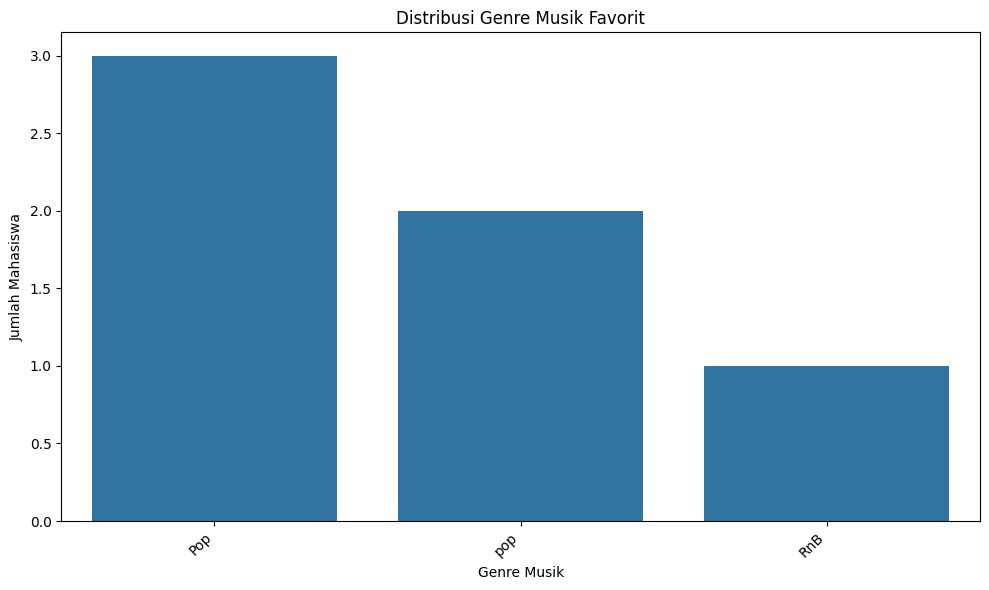


Genre musik favorit saya: Pop
Jumlah mahasiswa dengan genre musik favorit Pop: 3
Persentase: 50.00%
Genre musik favoritmu termasuk dominan.


In [ ]:
# Jawaban Soal 5

# meghitung gendre musik
genre_counts = data["Genre musik"].value_counts()

# membuat bar chart untuk distribusi gentre musik
plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.index, y=genre_counts.values)
plt.title("Distribusi Genre Musik Favorit")
plt.xlabel("Genre Musik")
plt.ylabel("Jumlah Mahasiswa")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Masukkan genre musik favoritmu
genre_favorit_saya = "Pop"

# menentukan apakah genre musik favoritmu termasuk dominan atau minoritas?
if genre_favorit_saya in genre_counts.index:
    count_genre_kamu = genre_counts[genre_favorit_saya]
    total_mahasiswa = genre_counts.sum()
    percentage_genre_kamu = (count_genre_kamu / total_mahasiswa) * 100

    print(f"\nGenre musik favorit saya: {genre_favorit_saya}")
    print(f"Jumlah mahasiswa dengan genre musik favorit {genre_favorit_saya}: {count_genre_kamu}")
    print(f"Persentase: {percentage_genre_kamu:.2f}%")


    if percentage_genre_kamu > (100 / len(genre_counts.index)):
        print("Genre musik favoritmu termasuk dominan.")
    else:
        print("Genre musik favoritmu termasuk minoritas.")
else:
    print(f"\nGenre musik '{genre_favorit_saya}' tidak ditemukan dalam data.")

#Hasil

langka di atas digunakan untuk menghitung distribusi genre musik favorit mahasiswa, menampilkannya dalam bentuk grafik, serta menganalisis apakah genre musik favorit saya termasuk dominan (banyak dipilih) atau minoritas (jarang dipilih).

## Soal 6
Gunakan metode **IQR (Interquartile Range)** untuk mendeteksi outlier tinggi badan.

- Apakah tinggi badanmu termasuk outlier atau tidak?

In [ ]:
# Jawaban Soal 6

# Hitung Q1 dan Q3
Q1 = data["Tinggi badan (cm)"].quantile(0.25)
Q3 = data["Tinggi badan (cm)"].quantile(0.75)

# Hitung IQR (Interquartile Range)
IQR = Q3 - Q1

# menentukan batas bawah dan batas atas untuk outlier
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Batas bawah outlier: {batas_bawah}")
print(f"Batas atas outlier: {batas_atas}")


# Masukkan tinggi badanmu
tinggi_badan_saya = 160

# Periksa apakah tinggi badanmu termasuk outlier
if tinggi_badan_saya < batas_bawah or tinggi_badan_saya > batas_atas:
    print(f"\nTinggi badanmu ({tinggi_badan_saya} cm) termasuk outlier.")
else:
    print(f"\nTinggi badanmu ({tinggi_badan_saya} cm) tidak termasuk outlier.")


Q1: 166.25
Q3: 170.0
IQR: 3.75
Batas bawah outlier: 160.625
Batas atas outlier: 175.625

Tinggi badanmu (160 cm) termasuk outlier.


Langka diatas analisis menggunakan IQR menunjukkan apakah tinggi badanmu termasuk nilai normal atau outlier. Pada contoh ini, tinggi badanmu 160 cm masih berada dalam rentang wajar, sehingga tidak termasuk outlier.

## Soal 7
Bersihkan kolom **Asal kelas** (hapus spasi berlebih, seragamkan huruf kapitalisasi).

- Hitung jumlah mahasiswa per kelas.
- Apakah kamu termasuk di kelas dengan jumlah terbanyak, menengah, atau sedikit?

In [ ]:
# Jawaban Soal 7 (dikerjakan kembali)

# Bersihkan kolom
data["Asal kelas"] = data["Asal kelas"].str.strip().str.upper()

# menghitung jumlah mahasiswa per kelas
jumlah_mahasiswa_per_kelas = data["Asal kelas"].value_counts().reset_index()
jumlah_mahasiswa_per_kelas.columns = ["Asal kelas", "Jumlah Mahasiswa"]

print("Jumlah mahasiswa per kelas:")
display(jumlah_mahasiswa_per_kelas)

# Masukkan asal kelas

asal_kelas_saya = "2B"

# Tentukan jumlah mahasiswa di kelasmu
if asal_kelas_saya in jumlah_mahasiswa_per_kelas["Asal kelas"].values:
    jumlah_kelas_kamu = jumlah_mahasiswa_per_kelas.loc[
        jumlah_mahasiswa_per_kelas["Asal kelas"] == asal_kelas_saya, "Jumlah Mahasiswa"
    ].values[0]

    print(f"\nAsal kelasmu: {asal_kelas_saya}")
    print(f"Jumlah mahasiswa di kelasmu: {jumlah_kelas_kamu}")

    # membandingkan jumlah mahasiswa di kelasmu dengan kelas lain
    kelas_sorted = jumlah_mahasiswa_per_kelas.sort_values(by="Jumlah Mahasiswa", ascending=False).reset_index(drop=True)
    posisi_kelas_kamu = kelas_sorted[kelas_sorted["Asal kelas"] == asal_kelas_saya].index[0] + 1
    total_kelas_unik = len(jumlah_mahasiswa_per_kelas)

    if posisi_kelas_kamu == 1:
        print("Kamu termasuk di kelas dengan jumlah terbanyak.")
    elif posisi_kelas_kamu == total_kelas_unik:
        print("Kamu termasuk di kelas dengan jumlah tersedikit.")
    else:
        print("Kamu termasuk di kelas dengan jumlah menengah.")
else:
    print(f"\nAsal kelas '{asal_kelas_saya}' tidak ditemukan dalam data.")

Jumlah mahasiswa per kelas:


,Asal kelas,Jumlah Mahasiswa
0,2B,2
1,2C,1
2,TI 2A,1
3,3D,1
4,2G,1



Asal kelasmu: 2B
Jumlah mahasiswa di kelasmu: 2
Kamu termasuk di kelas dengan jumlah terbanyak.


langka diatas menganalisis ini menghitung distribusi jumlah mahasiswa pada tiap kelas. Dengan memasukkan asal kelas sendiri, bisa diketahui jumlah mahasiswa di kelas saya dan bagaimana posisinya dibandingkan dengan kelas lain (apakah terbanyak, tersedikit, atau menengah)